# 03 Lightweight transformer: multilingual MiniLM-L12
Model selection survey, fine-tuning, evaluation and ONNX/INT8/vocabulary-pruned export for mobile.

Fine-tuning was run with `python -m src.train_transformer` (see `logs/`). Set `RUN_TRAINING = True` to re-train inside the notebook (about 5 minutes on a GPU / Apple MPS, longer on CPU).

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
RUN_TRAINING = False

## 1. Candidate survey (size, tokenisation of Hinglish, CPU latency)

In [2]:
sv = json.load(open('results/metrics/model_selection_survey.json'))
pd.DataFrame({k: {'params (M)': v['params_millions'], 'embedding share %': v['embedding_share_pct'],
  'fp32 MB': v['fp32_size_mb'], 'CPU ms (batch 1)': v['cpu_latency_ms_batch1'],
  'Hinglish pieces/word': v['tokenisation_hinglish']['pieces_per_word'],
  'Hinglish p99 tokens': v['tokenisation_hinglish']['p99_tokens']} for k, v in sv.items()}).T

,params (M),embedding share %,fp32 MB,CPU ms (batch 1),Hinglish pieces/word,Hinglish p99 tokens
paraphrase-multilingual-MiniLM-L12-v2,117.7,81.6,448.8,13.6,1.61,46.0
distilbert-base-multilingual-cased,135.3,67.8,516.2,15.7,1.87,61.0
xlm-roberta-base,278.0,69.1,1060.7,31.3,1.61,46.0
"hing-bert (L3Cube, Hinglish)",109.5,21.4,417.7,31.0,1.73,44.0


In [3]:
for k, v in sv.items(): print(f'{k:40s}', ' '.join(v['sample_tokens']))

paraphrase-multilingual-MiniLM-L12-v2    ▁Aap ka ▁S BI ▁account ▁band ▁ho ▁ja y ega . ▁KY C ▁update ▁karne ▁ke ▁liye ▁a bhi ▁link ▁open ▁karo .
distilbert-base-multilingual-cased       Aa ##pka SB ##I account band ho ja ##ye ##ga . K ##Y ##C update karne ke li ##ye ab ##hi link open karo .
xlm-roberta-base                         ▁Aap ka ▁S BI ▁account ▁band ▁ho ▁ja y ega . ▁KY C ▁update ▁karne ▁ke ▁liye ▁a bhi ▁link ▁open ▁karo .
hing-bert (L3Cube, Hinglish)             aa ##p ##ka sb ##i account band ho jay ##ega . ky ##c update ka ##rne ke li ##ye ab ##hi link open ka ##ro .


## 2. Fine-tuning

In [4]:
if RUN_TRAINING:
    from src.train_transformer import train
    train('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', lr=8e-5)
for name in ['paraphrase-multilingual-MiniLM-L12-v2', 'distilbert-base-multilingual-cased']:
    f = Path(f'results/metrics/transformer_training_{name}.json')
    if f.exists():
        info = json.load(open(f))
        print(name, '| device', info['device'], '| epochs', info['epochs_run'], '| train time', info['train_time_s'], 's')
        print('   best val:', info['val_metrics_best'])

paraphrase-multilingual-MiniLM-L12-v2 | device mps | epochs 6 | train time 276.5 s
   best val: {'eval_loss': 0.3889, 'eval_macro_f1': 0.9252, 'eval_accuracy': 0.9728, 'eval_phishing_recall': 0.8427, 'eval_spam_recall': 0.8977, 'eval_runtime': 2.721, 'eval_samples_per_second': 351.71, 'eval_steps_per_second': 5.513, 'epoch': 6.0}
distilbert-base-multilingual-cased | device mps | epochs 8 | train time 799.9 s
   best val: {'eval_loss': 0.4147, 'eval_macro_f1': 0.9148, 'eval_accuracy': 0.9707, 'eval_phishing_recall': 0.9213, 'eval_spam_recall': 0.8409, 'eval_runtime': 9.5679, 'eval_samples_per_second': 100.022, 'eval_steps_per_second': 1.568, 'epoch': 8.0}


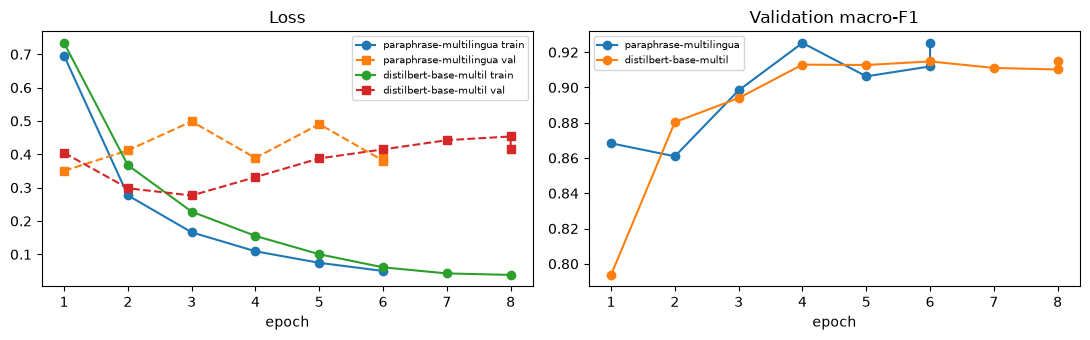

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name in ['paraphrase-multilingual-MiniLM-L12-v2', 'distilbert-base-multilingual-cased']:
    f = Path(f'results/metrics/transformer_training_{name}.json')
    if not f.exists(): continue
    h = json.load(open(f))['history']
    ev = [x for x in h if 'eval_macro_f1' in x]; tr = [x for x in h if 'loss' in x and 'eval_loss' not in x]
    ax[0].plot([x['epoch'] for x in tr], [x['loss'] for x in tr], 'o-', label=name[:22]+' train')
    ax[0].plot([x['epoch'] for x in ev], [x['eval_loss'] for x in ev], 's--', label=name[:22]+' val')
    ax[1].plot([x['epoch'] for x in ev], [x['eval_macro_f1'] for x in ev], 'o-', label=name[:22])
ax[0].set_title('Loss'); ax[1].set_title('Validation macro-F1'); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
for a in ax: a.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 3. Test-set comparison (all models, same test split)

In [6]:
print(open('results/metrics/comparison_table.md').read())

|                                  |   TF-IDF + Logistic Regression |   TF-IDF + Multinomial NB |   TF-IDF + Linear SVM |   mMiniLM-L12 (PyTorch fp32) |   DistilBERT-multilingual (PyTorch fp32) |   mMiniLM-L12 ONNX int8 |   mMiniLM-L12 ONNX int8 + vocab pruning |
|:---------------------------------|-------------------------------:|--------------------------:|----------------------:|-----------------------------:|-----------------------------------------:|------------------------:|----------------------------------------:|
| Accuracy                         |                         0.9651 |                    0.9651 |                0.9672 |                       0.963  |                                   0.9577 |                  0.9619 |                                  0.9619 |
| Macro precision                  |                         0.8892 |                    0.8898 |                0.9024 |                       0.8864 |                                   0.8697 |             

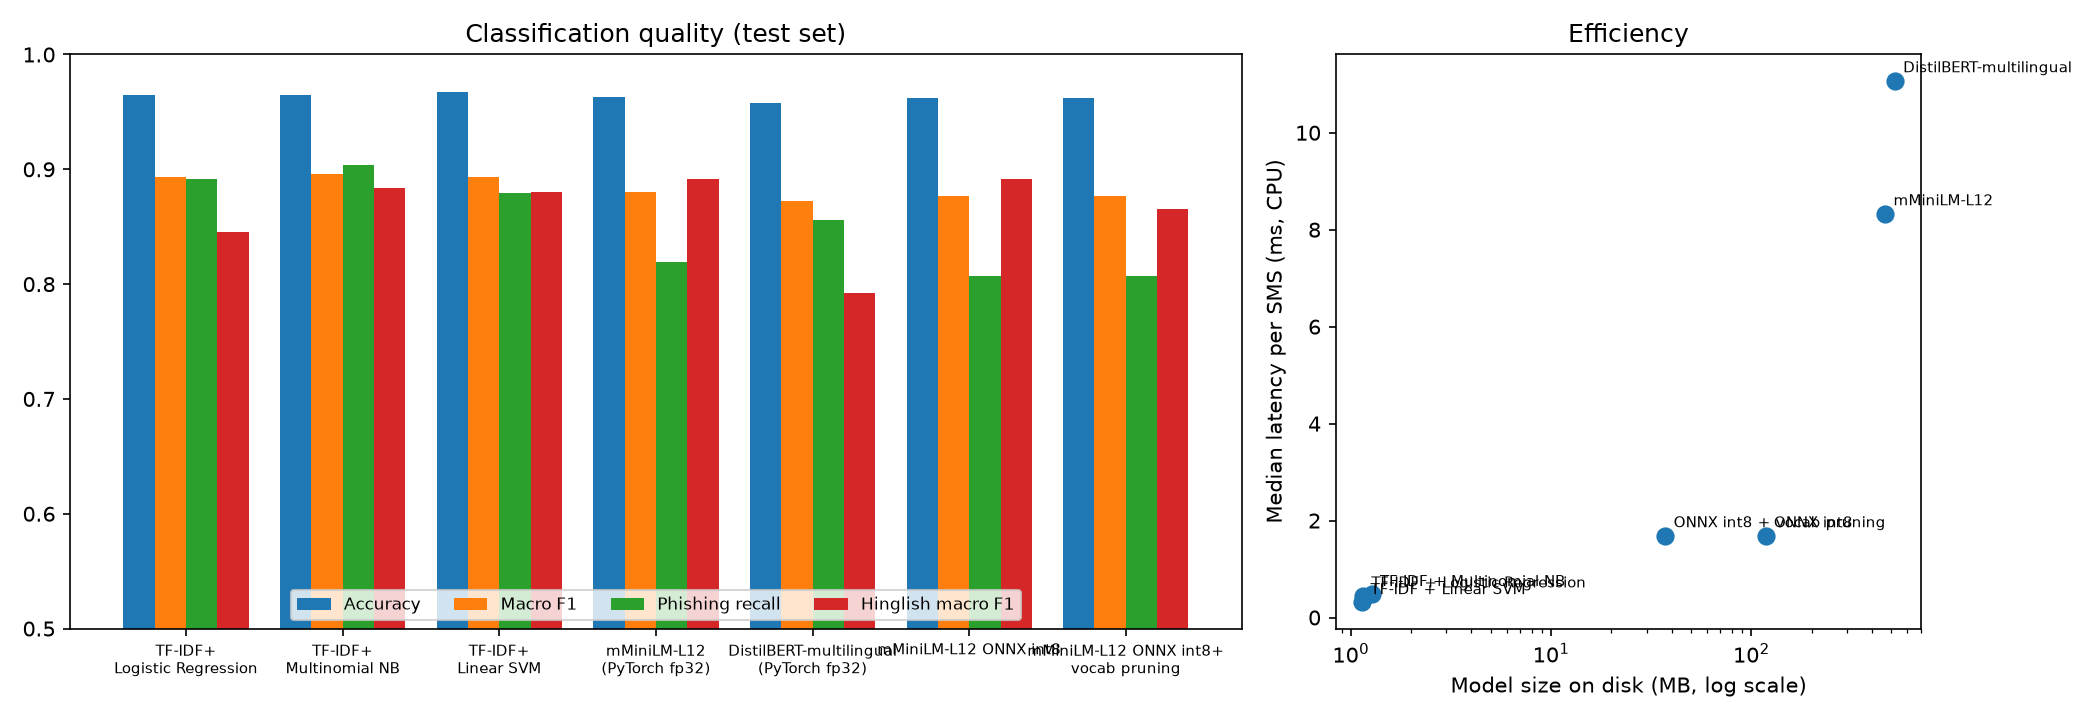

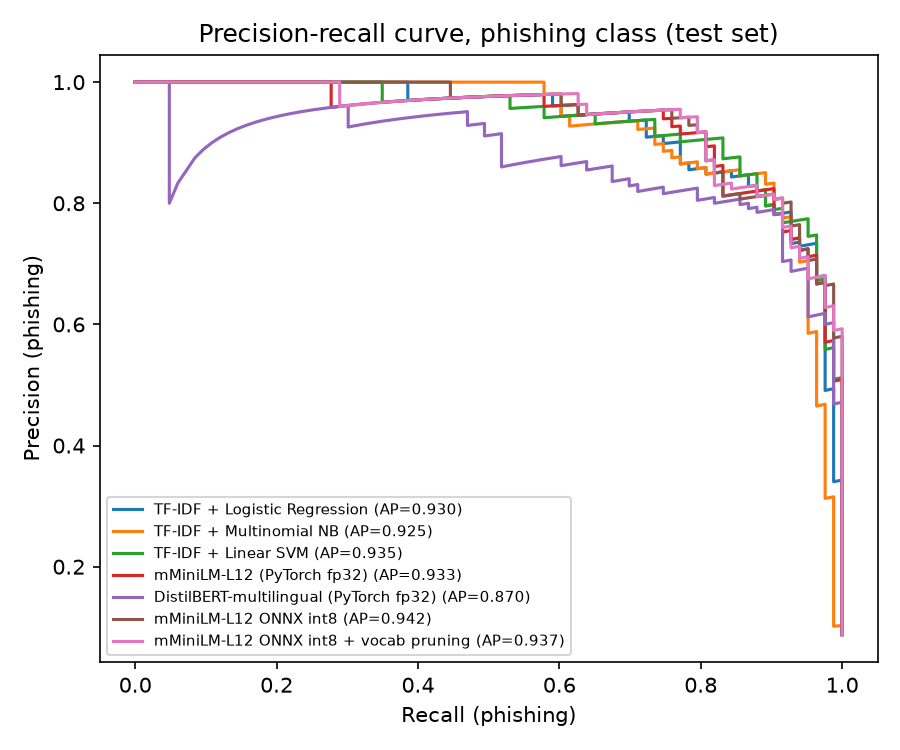

In [7]:
display(Image('results/graphs/model_comparison.png', width=950)); display(Image('results/graphs/pr_curves_phishing.png', width=500))

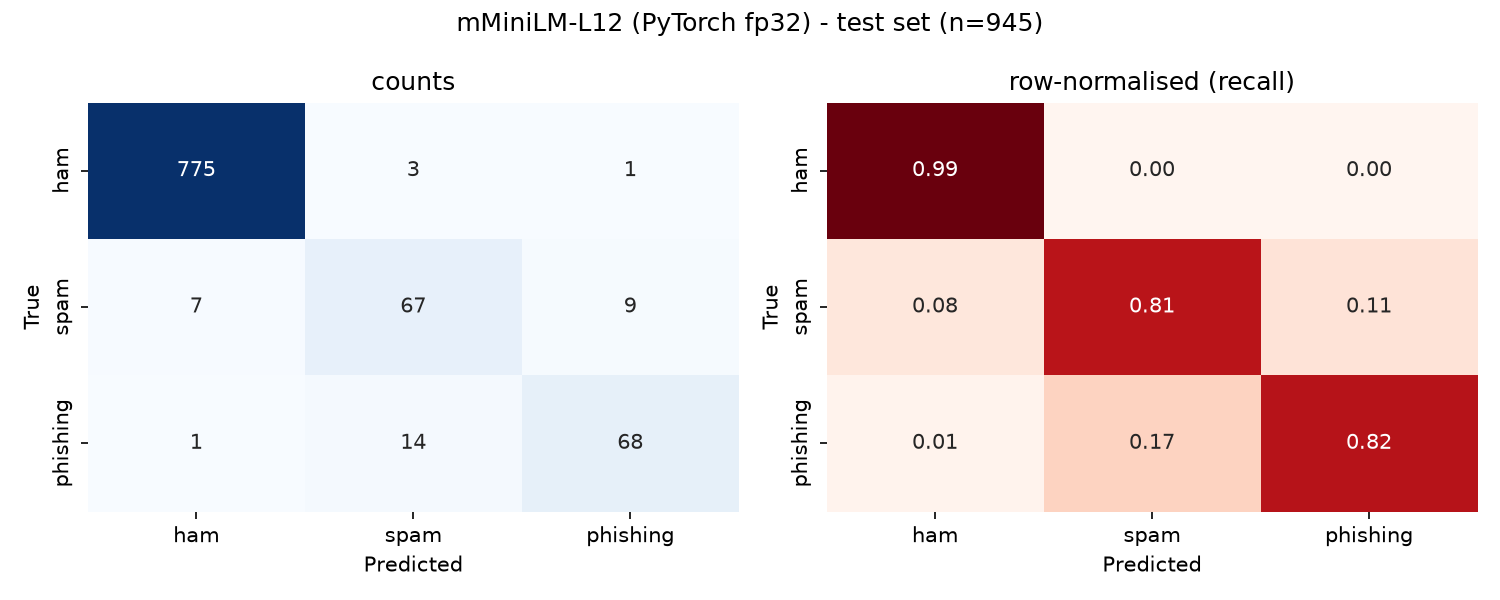

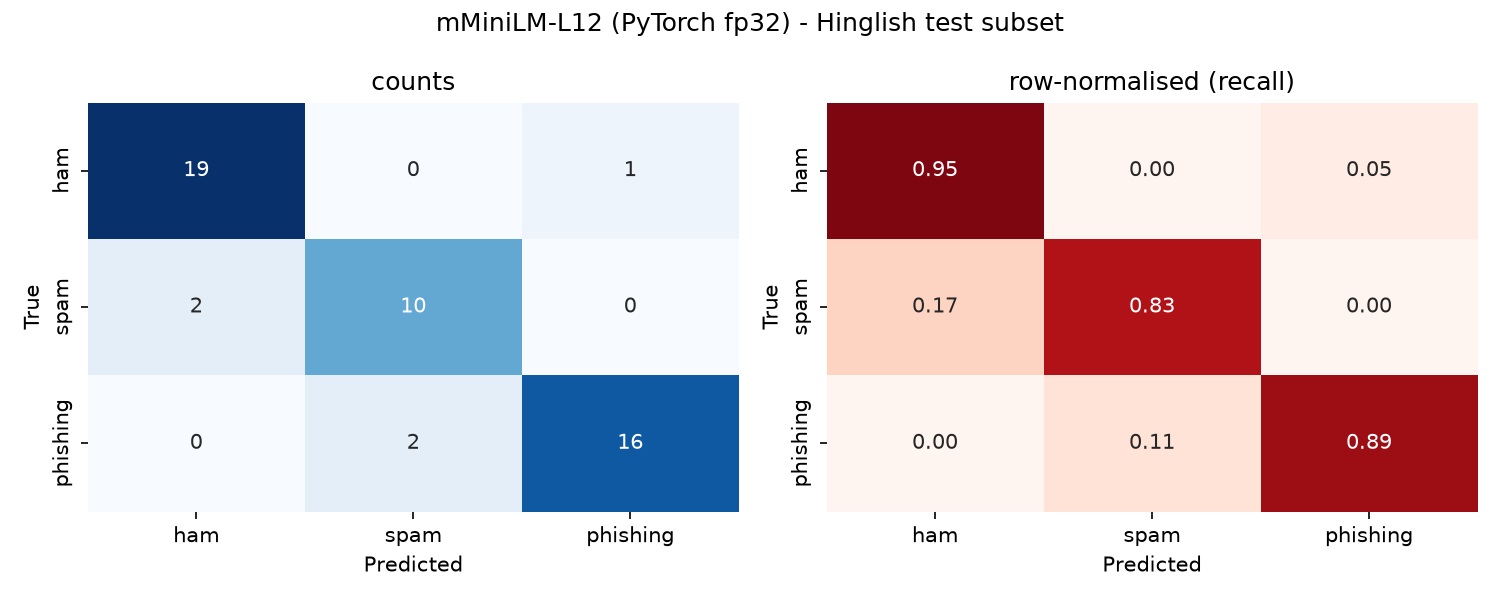

In [8]:
display(Image('results/confusion_matrices/cm_transformer.png', width=800)); display(Image('results/confusion_matrices/cm_transformer_hinglish.png', width=800))

## 4. Mobile optimisation (ONNX, INT8, vocabulary pruning) and verification

In [9]:
rep = json.load(open('results/metrics/onnx_export_report.json'))
print(json.dumps({k: rep[k] for k in ['pytorch_fp32_weights_mb','onnx_sizes_mb','vocab_pruning','verification']}, indent=1))
print(json.dumps(rep.get('end_to_end_model', {}), indent=1))

{
 "pytorch_fp32_weights_mb": 448.8,
 "onnx_sizes_mb": {
  "model_pruned_int8": 32.33,
  "model_fp32": 449.04,
  "model_int8": 112.79,
  "model_pruned_fp32": 121.46,
  "sms_classifier_e2e": 37.18
 },
 "vocab_pruning": {
  "original_vocab": 250037,
  "kept_vocab": 25103,
  "train_pieces": 8265,
  "keep_top": 20000,
  "test_token_oov_rate_pct": 2.073,
  "test_hinglish_token_oov_rate_pct": 4.623
 },
 "verification": {
  "model_fp32": {
   "label_agreement_with_pytorch_pct": 100.0,
   "max_abs_prob_diff": 0.0,
   "mean_abs_prob_diff": 0.0,
   "test_accuracy": 0.963
  },
  "model_int8": {
   "label_agreement_with_pytorch_pct": 99.89,
   "max_abs_prob_diff": 0.38349,
   "mean_abs_prob_diff": 0.001242,
   "test_accuracy": 0.9619
  },
  "model_pruned_fp32": {
   "label_agreement_with_pytorch_pct": 99.58,
   "max_abs_prob_diff": 0.90364,
   "mean_abs_prob_diff": 0.002819,
   "test_accuracy": 0.9619
  },
  "model_pruned_int8": {
   "label_agreement_with_pytorch_pct": 99.58,
   "max_abs_prob_diff

In [10]:
import subprocess
print(subprocess.run([sys.executable, 'deployment/mobile_inference.py',
  'Aapka SBI account band ho jayega. KYC update karne ke liye abhi link open karo.',
  'Kal college lecture 10 baje hai, time pe aa jana.', '--benchmark'], capture_output=True, text=True).stdout)

{"sms": "Aapka SBI account band ho jayega. KYC update karne ke liye abhi link open karo.", "label": "phishing", "confidence": 0.9911, "scores": {"ham": 0.0027, "spam": 0.0063, "phishing": 0.9911}}
{"sms": "Kal college lecture 10 baje hai, time pe aa jana.", "label": "ham", "confidence": 0.9976, "scores": {"ham": 0.9976, "spam": 0.0013, "phishing": 0.0011}}
{"variant": "model_pruned_int8", "threads": 2, "runs": 300, "median_ms": 1.81, "p95_ms": 2.22}

